In [2]:
import os
import sys

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import cv2
import cv2 as cv

In [4]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans

#from cvxopt import matrix, solvers
#import math

#from scipy.spatial.distance import cdist 
#from random import sample
#from sklearn.model_selection import train_test_split
#from sklearn.mixture import GaussianMixture
#from sklearn.ensemble import RandomForestClassifier
#from sklearn.datasets import make_classification
#from sklearn.metrics import confusion_matrix
#from sklearn.pipeline import make_pipeline
#from sklearn.preprocessing import StandardScaler
#from sklearn.cluster import KMeans
#from sklearn.svm import SVC
#from sklearn.gaussian_process import GaussianProcessClassifier
#from sklearn.gaussian_process.kernels import RBF
#from sklearn.metrics import pairwise_distances
#from scipy import stats

#from utils import *
#from class_utils import *

import Orange
from orangecontrib.spectroscopy import data
from orangecontrib.spectroscopy.data import getx
from Orange.data.io import FileFormat
#import Orange.data.io.FileFormat.read_spectra as read_spectra

In [5]:
def read_spectra(self):
        channels = self.get_channels()

        for c, label in channels.items():
            if label.decode("utf-8") == self.sheet:
                self.data_signal = c
                break
        else:
            self.data_signal = list(channels.keys())[0]

        import h5py
        hdf5_file = h5py.File(self.filename,'r')
        keys = list(hdf5_file.keys())

        hyperspectra = False
        intensities = []
        wavenumbers = []
        x_locs = []
        y_locs = []

        # load measurements
        for meas_name in filter(lambda s: s.startswith('Measurement'), keys):
            hdf5_meas = hdf5_file[meas_name]

            meas_keys = list(hdf5_meas.keys())
            meas_attrs = hdf5_meas.attrs

            # check if this measurement contains the selected data channel
            selected_signal = False
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                if hdf5_chan.attrs.keys().__contains__('DataSignal') and hdf5_chan.attrs['DataSignal'] == self.data_signal:
                    selected_signal = True
                    break
            if not selected_signal:
                continue

            # build range arrays
            spec_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeWavenumberStart'):
                    wn_start = meas_attrs['RangeWavenumberStart'][0]
                    wn_end = meas_attrs['RangeWavenumberEnd'][0]
                    wn_points = meas_attrs['RangeWavenumberPoints'][0]
                    spec_vals = np.linspace(wn_start, wn_end, wn_points)
            except:
                raise IOError("Error reading wavenumber range from " + self.filename)

            pos_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeXStart'):
                    x_start = meas_attrs['RangeXStart'][0]
                    x_points = meas_attrs['RangeXPoints'][0]
                    x_incr = meas_attrs['RangeXIncrement'][0]
                    x_end = x_start + x_incr * (x_points - 1)
                    x_min = min(x_start, x_end)
                    if meas_attrs.keys().__contains__('RangeYStart'):
                        y_start = meas_attrs['RangeYStart'][0]
                        y_points = meas_attrs['RangeYPoints'][0]
                        y_incr = meas_attrs['RangeYIncrement'][0]
                        y_end = y_start + y_incr * (y_points - 1)
                        y_min = min(y_start, y_end)

                        # construct the positions array
                        for iY in range(int(y_points)):
                            y = y_min + iY * abs(y_incr)
                            for iX in range(int(x_points)):
                                x = x_min + iX * abs(x_incr)
                                pos_vals.append([x, y])
                        pos_vals = np.array(pos_vals)
                else:
                    pos_vals = np.array([1])
            except:
                raise IOError("Error reading position data from " + self.filename)

            hyperspectra = pos_vals.shape[0] > 1

            # ignore backgrounds and unchecked data
            if not hyperspectra:
                if meas_attrs.keys().__contains__('IsBackground') and meas_attrs['IsBackground'][0]:
                    continue
                if meas_attrs.keys().__contains__('Checked') and not meas_attrs['Checked'][0]:
                    continue

            if len(wavenumbers) == 0:
                wavenumbers = spec_vals

            if hyperspectra:
                x_len = meas_attrs['RangeXPoints'][0]
                y_len = meas_attrs['RangeYPoints'][0]
                x_locs = pos_vals[:x_len,0]
                y_indices = np.round(np.linspace(0, pos_vals.shape[0] - 1, y_len)).astype(int)
                y_locs = pos_vals[y_indices,1]
            else:
                x_locs.append(meas_attrs['LocationX'][0])
                y_locs.append(meas_attrs['LocationY'][0])

            # load channels
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                chan_attrs = hdf5_chan.attrs

                signal = chan_attrs['DataSignal']
                if signal != self.data_signal:
                    continue

                data = hdf5_chan['Raw_Data']
                if hyperspectra:
                    rows = meas_attrs['RangeYPoints'][0]
                    cols = meas_attrs['RangeXPoints'][0]
                    intensities = np.reshape(data, (rows,cols,data.shape[1])) # organized rows, columns, wavelengths
                    break
                else:
                    intensities.append(data[0,:])

        #intensities = np.array(intensities)
        #features = np.array(wavenumbers)
        intensities = intensities
        features = np.array(wavenumbers)
        x_locs = np.array(x_locs).flatten()
        y_locs = np.array(y_locs).flatten()
        if hyperspectra:
            return _spectra_from_image(intensities, features, x_locs, y_locs)
        else:
            spectra = intensities

            # locations
            x_loc = y_loc = np.arange(len(spectra))
            metas = np.array([x_locs[x_loc], y_locs[y_loc]]).T

            domain = Orange.data.Domain([], None,
                                        metas=[Orange.data.ContinuousVariable.make("map_x"),
                                               Orange.data.ContinuousVariable.make("map_y")]
                                        )
            data = Orange.data.Table.from_numpy(domain, X=np.zeros((len(spectra), 0)),
                                                metas=np.asarray(metas, dtype=object))
            return features, spectra, data
        
Orange.data.io.FileFormat.read_spectra = read_spectra

In [13]:
path = '../spectral_libraries/OPTIR/Pilot_Phase_Field_Samples/'
files = os.listdir(path)

In [15]:
for i, f in enumerate(files):
    if f[-5:] != '.ptir':
        files.remove(f)
files

['MEC_02_066_ICB_AlSI_1_054261023_05252023_Run2.ptir',
 'MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2.ptir',
 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run1.ptir',
 'MEC_02_074_IAO_AlSI_1_04261023_05252023_Run3.ptir',
 'MEC_02_066_ICB_AlSI_1_054261023_05252023_Run3.ptir',
 'MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir',
 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run2.ptir',
 'MEC_02_066_FHS_AlSI_1_051023_06072023_Run2.ptir',
 'MEC_02_066_FHS_AlSI_1_051023_06072023_Run3.ptir',
 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run3.ptir',
 'MEC_02_066_ICB_AlSI_1_054261023_05252023_Run1.ptir',
 'MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1.ptir']

In [16]:
'MEC_02_066_FHS_AlSI_1_051023_06072023_Run2.ptir'

'MEC_02_066_FHS_AlSI_1_051023_06072023_Run2.ptir'

In [17]:
files = ['MEC_02_068_FHS_AlSI_1_051023_06072023_Run1']
spectra_list = []
for f in files:
    absolute_filename = FileFormat.locate(path + f)
    reader = FileFormat.get_reader(absolute_filename)
    spectra = read_spectra(reader)
    spectra = Orange.data.Table(path + f)
    spectra_list.append(spectra)    

In [18]:
spectra = Orange.data.Table(path + 'MEC_02_068_FHS_AlSI_1_051023_06072023_Run1')
coords = spectra.to_pandas_dfs()[2]
coords = np.float64(coords)

In [19]:
dir_paht = 'Al_Si_#1/'

In [20]:
image = cv.imread('Al_Si_1/DC AlSi 1/DC_AlSi_Run1.tif')

[ WARN:0@11.431] global loadsave.cpp:244 findDecoder imread_('Al_Si_1/DC AlSi 1/DC_AlSi_Run1.tif'): can't open/read file: check file path/integrity


In [21]:
dir_paht = 'Run1_Exported_20X_Mosaic_Images/'
sys.path.append(dir_paht)
files_img = os.listdir(dir_paht)
files_img.remove('Coordinates_and_Diagram.pdf')
files_img = list(np.sort(files_img))

In [22]:
images = [cv.imread(os.path.join(dir_paht, x)) if x[-3:] == 'tif' else None 
          for x in files_img]
images = [cv.cvtColor(image, cv.COLOR_BGR2RGB) for image in images]
#whole_image = np.concatenate([np.concatenate(images[4*i:4*(i+1)],1) for i in range(4)],0)

In [23]:

whole_image = np.concatenate(
    [
    np.concatenate(images[0:4],1),
    np.concatenate(images[4:8][::-1],1),
    np.concatenate(images[8:12],1),
    np.concatenate(images[12:16][::-1],1)
    ]
)

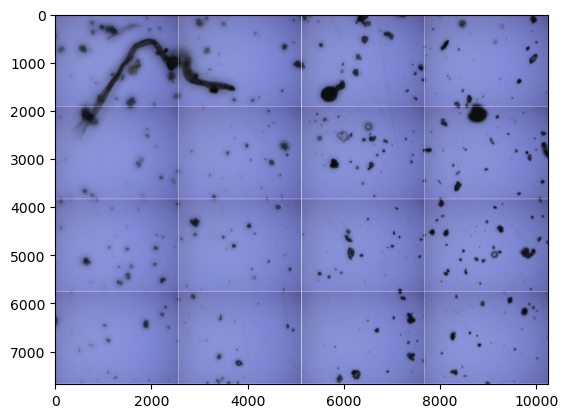

In [24]:
plt.imshow(whole_image)

In [25]:
coors_ref = [9633.11, 3711.33, 10890.84, 2768.57]
coors_ref

[9633.11, 3711.33, 10890.84, 2768.57]

In [26]:
table_results = pd.read_csv('../spectral_libraries/Pilot_Phase_Field_Samples_results/table_results.csv')
hits_index = table_results.query('school == "FHS" and run == "Run1"')['sample_id'].to_numpy()
#MEC_02_066_FHS_AlSI_1_051023_06072023_Run2

In [27]:
background = pd.read_csv('../spectral_libraries/OPTIR/Pilot_Phase_Field_Samples/data_background.csv')
bg_index = background.query('school == "FHS" and run == "Run1"')['sample_id'].to_numpy()

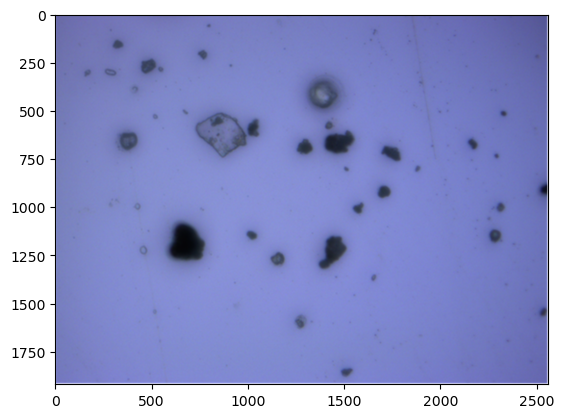

In [28]:
plt.imshow(images[5])

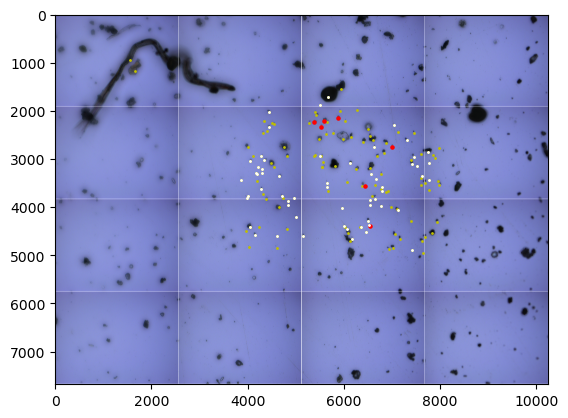

In [29]:
plt.imshow(whole_image)
#plt.scatter(coords_t[::-,0], coords_t[::-1,1], c='y')
#plt.scatter(10240* (coords[:,0]-9633.11) /(10890.84 - 9633.11), 7680* (coords[:,1]-2768.57) /(3711.33 - 2768.57), c='y',s=.5)

alpha = 10240/(10890.84 - 9633.11)
a = 0#115

beta = 7680/(3711.33 - 2768.57)
b = 0#110

new_coord_x = alpha*(coords[:,0]- 9633.11)
new_coord_y = beta*(3711.33-(coords[:,1]))

new_coord_x_aug = (new_coord_x.reshape(156,1) + np.arange(-10,10).reshape(1,20)).reshape(-1,1)
new_coord_y_aug = (new_coord_y.reshape(156,1) + np.arange(-10,10).reshape(1,20)).reshape(-1,1)

plt.scatter(
     new_coord_x,
    new_coord_y,
    c='y', s=1)

plt.scatter(
     new_coord_x[hits_index],
    new_coord_y[hits_index],
    c='r', s=5)

plt.scatter(
     new_coord_x[bg_index],
    new_coord_y[bg_index],
    c='w', s=1)



In [30]:
coords.shape

(156, 2)

In [31]:
hits_index.shape

(7,)

In [32]:
new_coord_x[hits_index]

array([6444.85191575, 6997.66531768, 5512.22726658, 5384.40173964,
       5584.27770666, 5879.81808496, 6545.80363035])

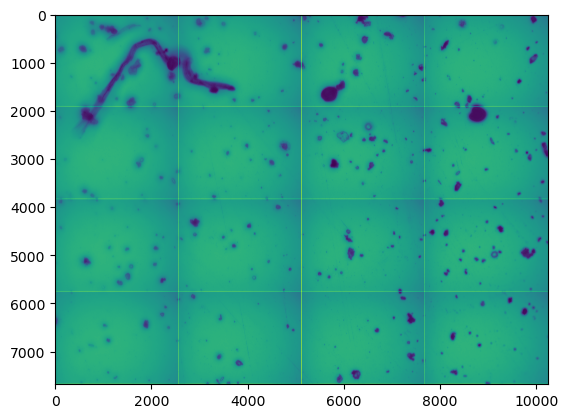

In [33]:
grayscale = cv.cvtColor(whole_image, cv.COLOR_BGR2GRAY)
plt.imshow(grayscale)

(array([  545913.,   788197.,   783545.,   962544.,  4716101., 39255205.,
        31128302.,   150357.,    81395.,   231641.]),
 array([  6. ,  30.9,  55.8,  80.7, 105.6, 130.5, 155.4, 180.3, 205.2,
        230.1, 255. ]),
 <BarContainer object of 10 artists>)

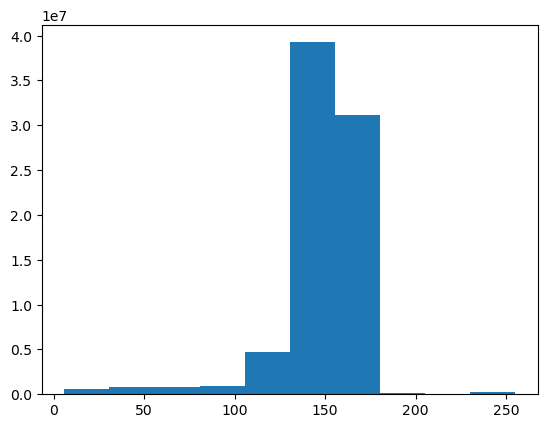

In [34]:
plt.hist(grayscale.flatten())

In [35]:
low = np.array([0])
high = np.array([115])

gray = cv.cvtColor(whole_image, cv.COLOR_BGR2GRAY)

ret, thresh = cv.threshold(gray,0,255, 9)#,cv.THRESH_BINARY_INV+cv.THRESH_OTSU)
thresh = cv.inRange(grayscale, low, high)

# noise removal
kernel = np.ones((3,3),np.uint8)
opening = cv.morphologyEx(thresh,cv.MORPH_OPEN,kernel, iterations = 2)
# sure background area
sure_bg = cv.dilate(opening,kernel,iterations=3)
# Finding sure foreground area
dist_transform = cv.distanceTransform(opening,cv.DIST_L2,5)
ret, sure_fg = cv.threshold(dist_transform,0.7*dist_transform.max(),255,0)
# Finding unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv.subtract(sure_bg,sure_fg)

dist_transform = cv.distanceTransform(opening,cv.DIST_L2,5)
ret, sure_fg = cv.threshold(dist_transform,0.01*dist_transform.max(),255,0)

mask = (sure_fg==255)

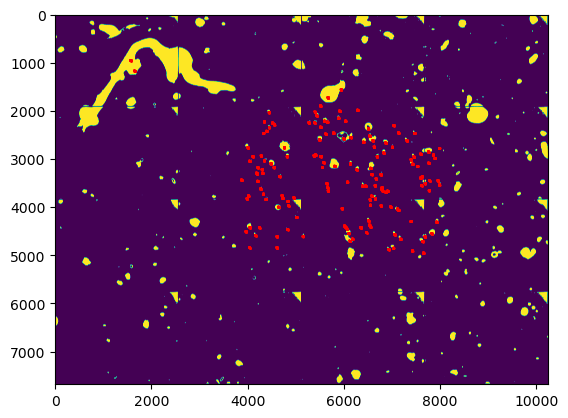

In [36]:
plt.imshow(mask)
plt.scatter(
     new_coord_x_aug,
    new_coord_y_aug,
    c='r', s=.5)


In [37]:
np.arange(16).reshape(4,4).flatten()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])

In [38]:
new_coord_x_aug.shape

(3120, 1)

In [39]:
mask_long = np.concatenate([
    (mask.flatten() * 1)[:, None],
    np.concatenate([np.arange(10240)] * 7680)[:, None], 
    np.concatenate([np.ones(10240)*i for i in range(7680)])[:, None]
    ],1)

In [40]:
mask_long_pos = mask_long[mask_long[:,0] == 1,:]

In [41]:
x_coord = np.concatenate([new_coord_x[:,None], new_coord_y[:,None]], 1)
x_coord.shape

(156, 2)

In [42]:
x_mask = mask_long_pos[:,1:]

In [43]:
x_mask.shape

(3762770, 2)

In [44]:
from sklearn.metrics import pairwise_distances

In [45]:
distances = pairwise_distances(x_mask, x_coord)

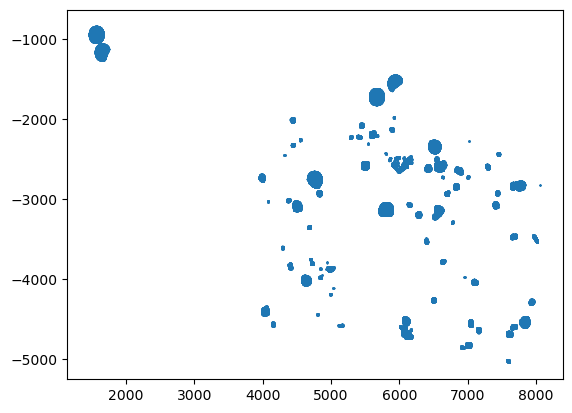

In [46]:
keep = distances.min(1) < 100
plt.scatter(mask_long_pos[keep,1],-mask_long_pos[keep,2], s=.1)

In [47]:
x_mask_keep = np.vstack([mask_long_pos[keep,1], mask_long_pos[keep,2]]).T
x_mask_keep.shape

(407397, 2)

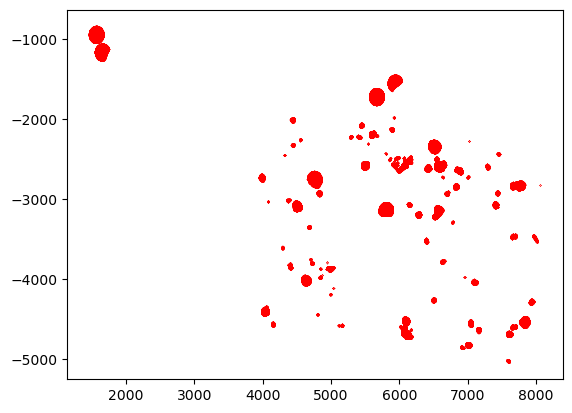

In [48]:
plt.scatter(x_mask_keep[:,0], -x_mask_keep[:,1],c='r',s=.01)

In [49]:
x_mask_keep.shape

(407397, 2)

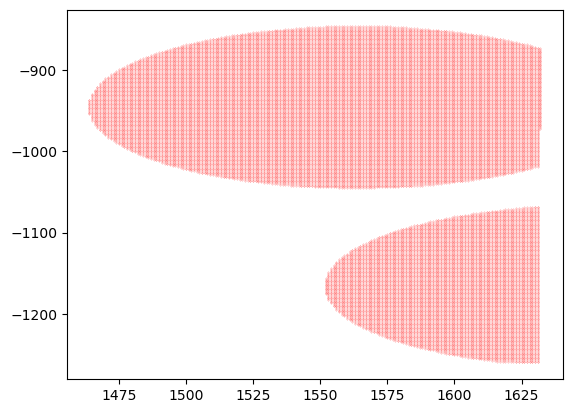

In [50]:
lim = 40001
x_mask_keep_sorted = pd.DataFrame(x_mask_keep).sort_values(by=[0,1]).to_numpy()
plt.scatter(x_mask_keep_sorted[:lim,0], -x_mask_keep_sorted[:lim,1],c='r',s=.01)

In [51]:
#x_mask_keep_sorted[lim-10:lim+300,:]

In [52]:
index_x_keep = np.int64(mask_long_pos[keep,1])
index_y_keep = np.int64(mask_long_pos[keep,2])

In [53]:
mask_keep = np.zeros_like(mask)#.copy()
mask_keep[index_y_keep, index_x_keep] = 1

In [54]:
mask

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

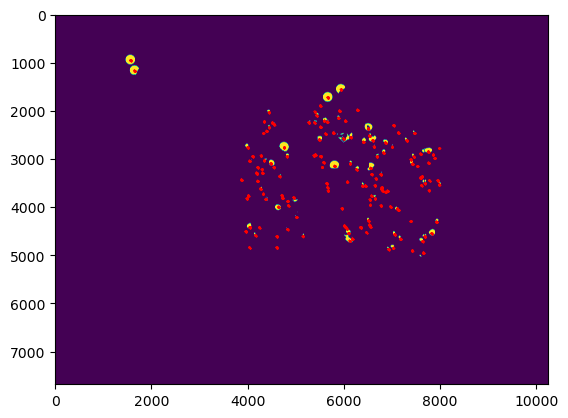

In [55]:
plt.imshow(mask_keep)
plt.scatter(
     new_coord_x_aug,
    new_coord_y_aug,
    c='r', s=.1)

In [56]:
((1-mask_keep.astype('uint8')) * 255)

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], dtype=uint8)

In [57]:
gray = cv.cvtColor(whole_image, cv.COLOR_BGR2GRAY)
binary = cv.threshold(gray, 0, 255, cv.THRESH_BINARY | cv.THRESH_OTSU)[1]
ret, labels = cv.connectedComponents(binary)

In [58]:
binary

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], dtype=uint8)

In [59]:
ret, labels = cv.connectedComponents(((mask_keep.astype('uint8')) * 255))

In [60]:
ret, labels = cv.connectedComponents(((mask.astype('uint8')) * 255))

In [61]:
np.unique(labels)

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [64]:
mask_list[0].shape

(7680, 10240)

In [65]:
plt.imshow(mask_list[i])#.shape

IndexError: list index out of range

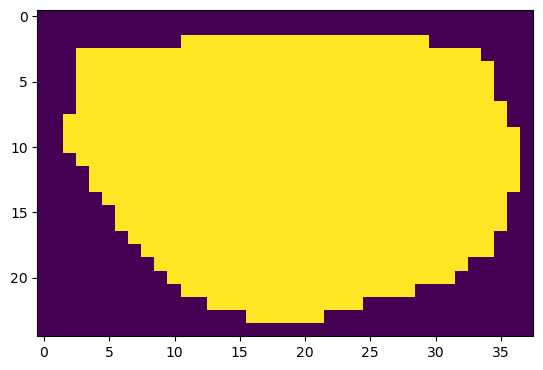

In [118]:
i = 2
min1, min2, max1,max2 =(np.where(mask_list[i] == 1)[0].min()-2,
  np.where(mask_list[i] == 1)[1].min()-2,
 np.where(mask_list[i] == 1)[0].max()+2,
 np.where(mask_list[i] == 1)[1].max()+2)

plt.imshow(mask_list[i][min1:max1, min2:max2])#.shape
mask_1 = mask_list[i][min1:max1, min2:max2]

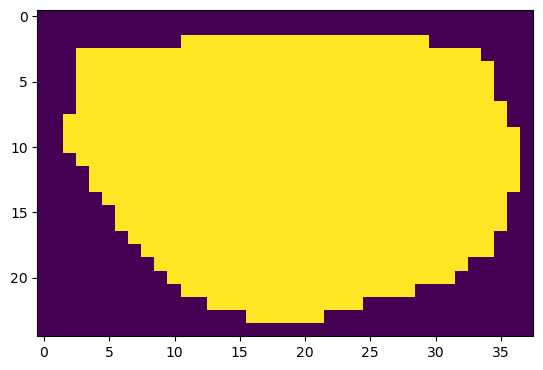

In [119]:
plt.imshow(np.uint8(mask_1))

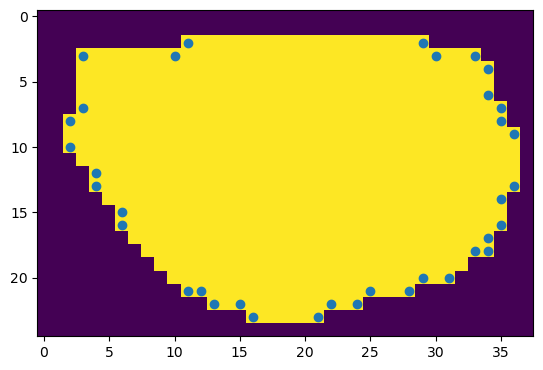

In [138]:
img = np.uint8(mask_1)
plt.imshow(img)
plt.scatter(cnt[:,0,0], cnt[:,0,1])

In [146]:
(img - img_).sum()

86

In [ ]:
plt.imshow(img)
plt.imshow(img_, alpha=.1)
plt.scatter(cnt[:,0,0], cnt[:,0,1])

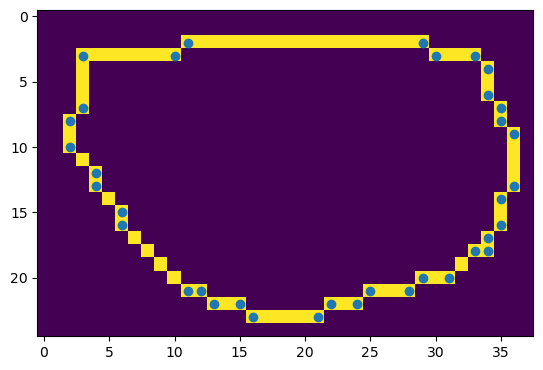

In [147]:
plt.imshow(img - img_)
plt.scatter(cnt[:,0,0], cnt[:,0,1])

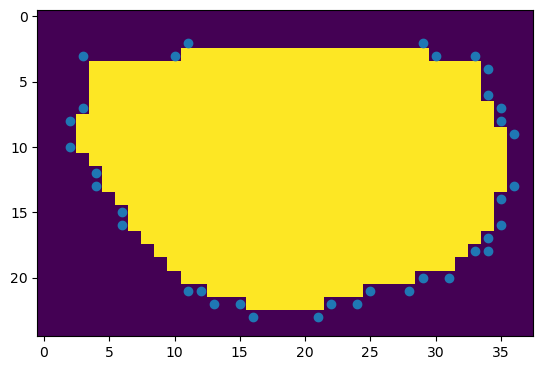

In [140]:
plt.imshow(img1)
plt.scatter(cnt[:,0,0], cnt[:,0,1])

In [132]:
np.sum(img)

611

In [133]:

contours,hierarchy = cv.findContours(np.uint8(mask_1), cv.RETR_TREE,cv.CHAIN_APPROX_SIMPLE)
print("Number of contours in image:",len(contours))
cnt = contours[0]

Number of contours in image: 1


In [134]:
area = cv.contourArea(cnt)
perimeter = cv.arcLength(cnt, True)
perimeter = round(perimeter, 4)
area, perimeter

(567.0, 95.9411)

In [139]:
img_ = img.copy()
img1 = cv.drawContours(img_, [cnt], -1, (0,255,255), 1)

Area: 567.0
Perimeter: 95.9411


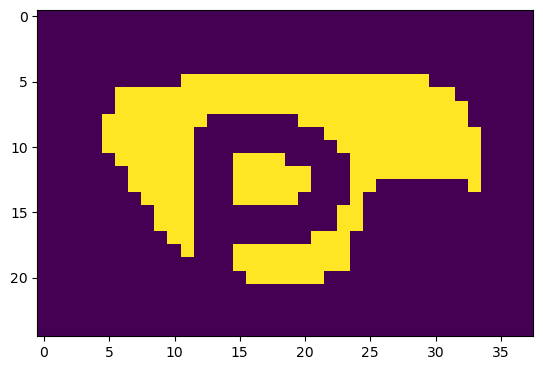

In [127]:
area = cv.contourArea(cnt)
perimeter = cv.arcLength(cnt, True)
perimeter = round(perimeter, 4)
print('Area:', area)
print('Perimeter:', perimeter)
img1 = cv.drawContours(img, [cnt], -1, (0,255,255), 3)
x1, y1 = cnt[0,0]
cv.putText(img1, f'Area:{area}', (x1, y1), cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
cv.putText(img1, f'Perimeter:{perimeter}', (x1, y1+20), cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

plt.imshow(img)
#cv.imshow("Image", img)
#cv.waitKey(0)
#cv.destroyAllWindows()

In [63]:
mask_list = []
for label in range(1,10):
    mask = np.zeros_like(labels)#np.array(labels, dtype=np.uint8)
    mask[labels == label] = 1
    mask_list.append(mask)
    #cv.imshow('component',mask)
    #cv.waitKey(0)

In [76]:
cv.imshow('component',mask_list[1])
#cv.waitKey(0)

error: OpenCV(4.7.0) /Users/runner/work/opencv-python/opencv-python/opencv/modules/highgui/src/precomp.hpp:155: error: (-215:Assertion failed) src_depth != CV_16F && src_depth != CV_32S in function 'convertToShow'


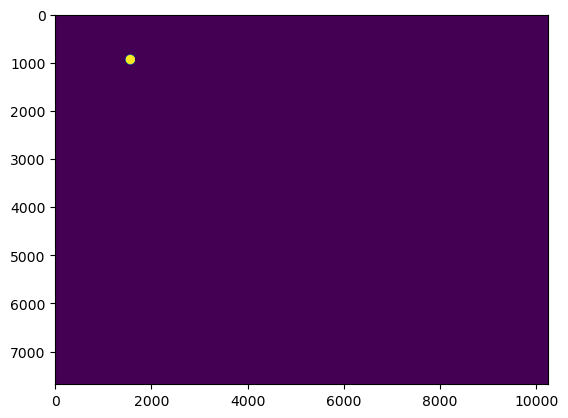

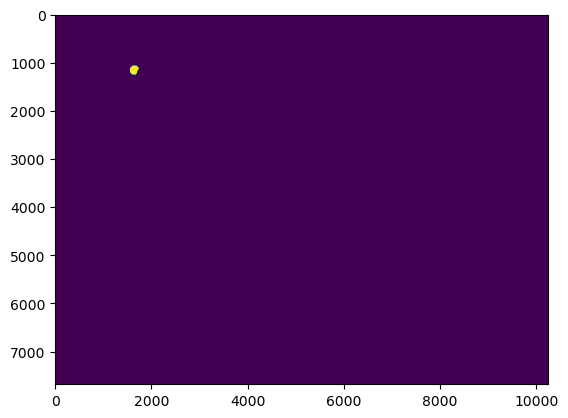

KeyboardInterrupt: 

In [77]:
for mask in mask_list[:10]:
    plt.imshow(mask)
    plt.show()

In [78]:
size_dist = [m.sum() for m in mask_list]

In [79]:
sizes_distr = np.array(size_dist) / (alpha*beta)

In [80]:
np.min(sizes_distr) ** 0.5

0.36837059050976717

In [81]:
sizes_distr[sizes_distr<100]

array([ 1.37204635, 32.79341556, 28.33049555, 20.61085014, 69.43157638,
        5.71434689, 14.21801879,  9.40831784,  4.10106162,  0.24123892,
        0.48247784, 13.82600555,  0.13569689, 11.38346149,  0.54278757,
        0.57294243, 65.75268287, 18.71109366, 19.17849406,  4.44784257,
        0.43724554,  2.75917014, 29.49145785, 70.14021571,  0.22616149,
       82.76002666,  0.63325216, 63.89815868,  5.020785  ,  2.75917014,
       45.47353624, 49.01673286,  0.13569689, 42.17157853, 22.23921285,
       28.48126988, 14.24817366,  0.98003311, 54.36922138, 23.30971055,
       49.57459786,  3.09087365, 12.71027555, 13.50937947, 25.3300865 ,
       30.20009718, 22.85738758,  5.6238823 ,  2.92502189, 24.51590515,
       13.22290825,  0.18092919,  6.49837338,  1.40220122, 11.2477646 ,
       45.80523975,  0.78402649,  0.18092919,  0.21108405,  7.64425825,
        0.34678095, 49.28812664,  0.34678095,  1.97514365, 28.76774109,
       41.56848123,  1.35696892, 48.47394529, 17.59536366,  7.85

(array([54., 13., 11.,  1.,  3.,  0.,  2.,  2.,  3.,  1.,  0.,  1.,  0.,
         0.,  1.,  0.,  1.,  2.,  0.,  2.]),
 array([1.35696892e-01, 2.38155584e+01, 4.74954199e+01, 7.11752814e+01,
        9.48551430e+01, 1.18535004e+02, 1.42214866e+02, 1.65894728e+02,
        1.89574589e+02, 2.13254451e+02, 2.36934312e+02, 2.60614174e+02,
        2.84294035e+02, 3.07973897e+02, 3.31653758e+02, 3.55333620e+02,
        3.79013481e+02, 4.02693343e+02, 4.26373204e+02, 4.50053066e+02,
        4.73732927e+02]),
 <BarContainer object of 20 artists>)

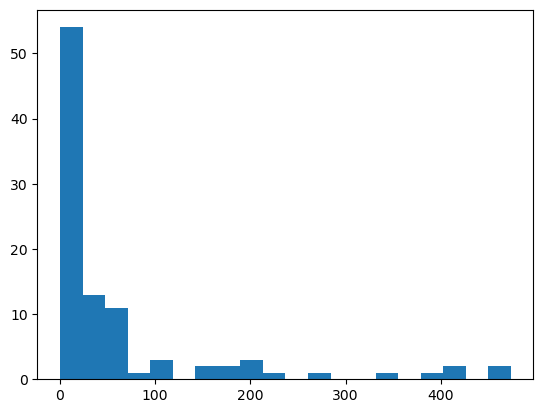

In [82]:
plt.hist(sizes_distr, 20)

## shape ratio

In [ ]:
contours = cv.findContours(binary, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)[1]
for cnt in contours:
    (x,y,w,h) = cv2.boundingRect(cnt)
    ROI = image[y:y+h,x:x+w]
    cv2.imshow('ROI', ROI)
    cv2.waitKey(0)

cv2.destroyAllWindows()

In [142]:


# getting mask with connectComponents
ret, labels = cv2.connectedComponents(binary)
for label in range(1,ret):
    mask = np.array(labels, dtype=np.uint8)
    mask[labels == label] = 255
    cv2.imshow('component',mask)
    cv2.waitKey(0)

# getting ROIs with findContours
contours = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[1]
for cnt in contours:
    (x,y,w,h) = cv2.boundingRect(cnt)
    ROI = image[y:y+h,x:x+w]
    cv2.imshow('ROI', ROI)
    cv2.waitKey(0)

cv2.destroyAllWindows()

NameError: name 'cv2' is not defined

(407397, 2)

In [72]:
from sklearn.cluster import KMeans

array([[1552.,  846.],
       [1553.,  846.],
       [1554.,  846.],
       ...,
       [7607., 5038.],
       [7608., 5038.],
       [7609., 5038.]])

In [82]:
kmeans = KMeans(n_clusters=50, random_state=0).fit(x_mask_keep)
labels = kmeans.labels_

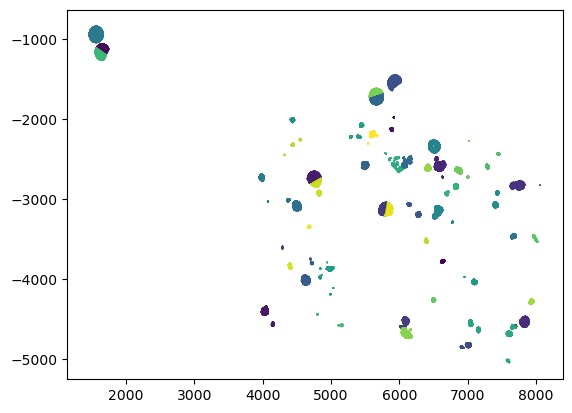

In [83]:
plt.scatter(x_mask_keep[:,0], -x_mask_keep[:,1],c=labels,s=.01)